In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import h5py

# 1. Configuração de Caminhos
# O fake_spectra busca por: base/snapdir_num/snap_num.0.hdf5
BASE_PATH = "/home/STORAGE/TNG50-4"
SNAP_NUM = 25

from fake_spectra.spectra import Spectra

In [2]:
# 2. Skewer Geometry
# On TNG50-4, we need to know the size of the box to find the center.
# read the Header.
snap_file = os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}/snap_{SNAP_NUM:03d}.0.hdf5")
with h5py.File(snap_file, 'r') as f:
    box_size = f['Header'].attrs['BoxSize'] # kpc/h comoving
    redshift = f['Header'].attrs['Redshift']

print(f"Redshift do Snapshot: {redshift:.2f}")
print(f"Tamanho da Caixa: {box_size} kpc/h")

Redshift do Snapshot: 3.01
Tamanho da Caixa: 35000.0 kpc/h


In [3]:
# Vamos colocar o skewer no centro (x, y) e atravessar em z (eixo 3)
center = box_size / 2.0
fs_cofm = np.array([[0.0, center, center]]) # The value on the skewer axis (x=0) is ignored
fs_axis = np.array([1]) # 1=x, 2=y, 3=z

In [49]:
# 3. Extração com Fake Spectra
# 'res' é a resolução em km/s. 1.0 km/s é um valor padrão para Lyman-alpha forest.
pixel_res_kms = 1

spec = Spectra(
    num=SNAP_NUM,
    base=BASE_PATH,
    cofm=fs_cofm,
    axis=fs_axis,
    res=pixel_res_kms,
    reload_file=True, # Força a extração dos dados do snapshot
    quiet=False
)

Reloading from snapshot (will save to:  /home/STORAGE/TNG50-4/snapdir_025/spectra.hdf5  )
1  sightlines. resolution:  1.000137852803097  z= 3.008131071630377


In [50]:
# Extraindo a profundidade óptica (Tau) de Lyman-alpha
# Elemento "H", Ion 1 (HI - Neutro), Linha 1215 (Lya)
tau = spec.get_tau("H", 1, 1215)
flux = np.exp(-tau[0]) # Convertendo Tau para Fluxo Transmitido

rank = 0 | Interpolation 9.1 percent done
rank = 0 | Interpolation 18.2 percent done
rank = 0 | Interpolation 27.3 percent done
rank = 0 | Interpolation 36.4 percent done
rank = 0 | Interpolation 45.5 percent done
rank = 0 | Interpolation 54.5 percent done
rank = 0 | Interpolation 63.6 percent done
rank = 0 | Interpolation 72.7 percent done
rank = 0 | Interpolation 81.8 percent done
rank = 0 | Interpolation 90.9 percent done


In [55]:
# 4. Processamento de Comprimento de Onda
v_max = spec.vmax      # Extensão da caixa em km/s
n_bins = spec.nbins    # Número de pixels
vel_axis = np.linspace(0, v_max, n_bins)

# Comprimento de onda observado: lambda = lambda_repouso * (1 + z) * (1 + v/c)
lambda_lya_rest = 1215.67  # Angstroms

c_kms = 2.99792458e5  # km/s    
lambda_obs = lambda_lya_rest * (1 + vel_axis / c_kms)

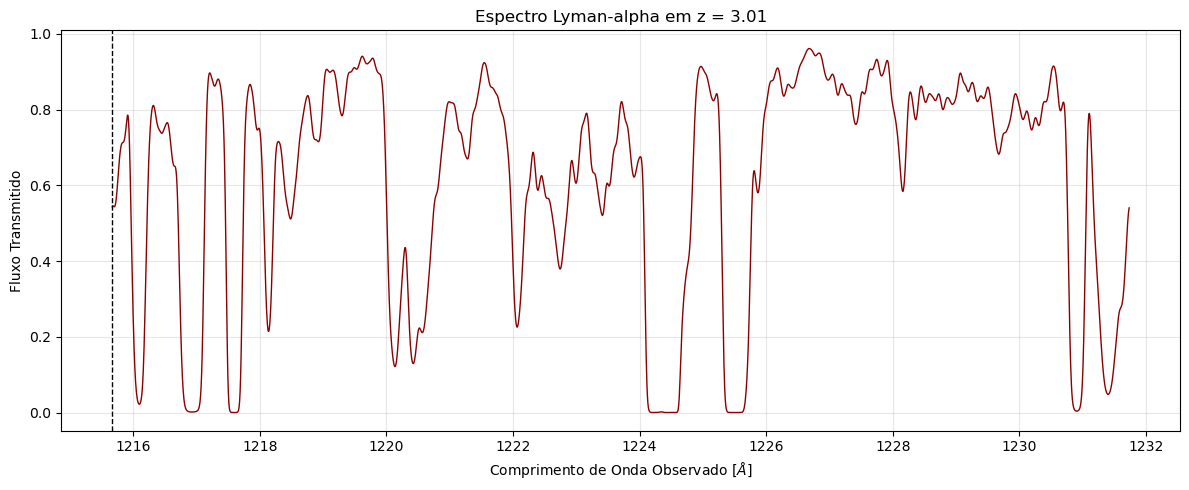

Média do fluxo transmitido: 0.6177


In [58]:
# 5. Visualização
plt.figure(figsize=(12, 5))

plt.plot(lambda_obs, flux, color='darkred', lw=1)
plt.axvline(1215.67, color='k', lw=1, ls='--', label='Lyman-alpha Rest Wavelength')
plt.xlabel(r"Comprimento de Onda Observado [$\AA$]")
plt.ylabel("Fluxo Transmitido")
plt.title(f"Espectro Lyman-alpha em z = {redshift:.2f}")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Média do fluxo transmitido: {np.mean(flux):.4f}")
